# Thu nhập 2010–2014: bốn câu hỏi

Ngày lập: **09/11/2026**. Chỉ dùng 2010 và 2014; mọi mức tiền dùng **triệu đồng/người/năm, theo giá 2010**.

1. Thu nhập bình quân đầu người có tăng không?
2. Thu nhập bình quân đầu người trong từng Q1–Q4 có tăng không?
3. Phương sai thu nhập đầu người có giảm không?
4. Chênh lệch thu nhập trung bình **Q4 − Q1** có giảm không?

Mỗi câu có: tham số → estimator → H₀/H₁ → điều kiện/phân phối → phép tính → kết luận. Câu 3 có giới hạn thực tế: công thức F trong lớp cần phân phối chuẩn, không thể ép dữ liệu đáp ứng giả định.

## 1. Định nghĩa và kiến thức sử dụng

Một quan sát là **một hộ**. `income` là thu nhập cả hộ trong cả năm, đơn vị nghìn đồng; `size` gồm mọi thành viên, kể cả trẻ em và người chưa lao động.

\[
Y_{it}=\frac{income_{it}}{size_{it}}\times\frac{100}{CPI_t}\times\frac1{1000}.
\]

- Bình quân cần kiểm định là trung bình của các giá trị $Y_{it}$, **mỗi hộ có trọng số bằng nhau**. Không lấy tổng thu nhập chia tổng người và coi đó là cùng estimator.
- Hai năm là hai mẫu độc lập theo mô hình làm việc đã thống nhất; không paired, không ghép theo số dòng. Trong mỗi năm, các quan sát được mô hình hóa là độc lập.
- Giữ `Quart` gốc của từng năm. Đây là so các nhóm cùng vị trí thu nhập, **không theo cùng hộ**. Suy luận theo Q coi nhãn nhóm như đã cho, chưa tính bất định do điểm cắt Quart được xác định từ mẫu.
- Không có trọng số, tầng/cụm khảo sát: “toàn quốc” ở đây là toàn mẫu có các địa bàn trên cả nước, chưa phải suy luận đã hiệu chỉnh thiết kế mẫu quốc gia.
- Mức ý nghĩa **5% cho từng phép kiểm định**. Các CI là khoảng riêng lẻ, chưa có bảo đảm đồng thời cho toàn bộ các câu; các p không phải bằng chứng độc lập.

| Nội dung | Tài liệu lớp |
|---|---|
| Mean, median, variance; phân biệt mức tuyệt đối và tương đối | Chap 2 |
| $E(\bar Y)=\mu$, $Var(\bar Y)=\sigma^2/n$; CLT | Chap 3, trang PDF 12–14 |
| Estimator khác giá trị ước lượng; $\bar Y$, $S^2$ với mẫu số $n-1$ | Lecture 4, trang 3–5; Chap 3 trang 16–17 |
| H₀/H₁, mức ý nghĩa, bác bỏ/không bác bỏ | Chap 6 |
| Hai mẫu độc lập, phương sai chưa biết và không giả sử bằng nhau | Chap 7 §7.2.4, trang 14 |
| So sánh hai phương sai bằng F, **cần tổng thể chuẩn** | Chap 7 §7.3, trang 19; Chap 3 trang 17 |
| Kiểm tra chuẩn bằng Jarque–Bera | Chap 9, trang 21 |

Câu 4 vận dụng CLT và phương sai của tổng các estimator độc lập để so **bốn mean**. Đây là bước suy rộng công thức, không phải một t-test hai mẫu được in nguyên dạng trong slide.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

SIGNIFICANCE_LEVEL = 0.05
BASE_YEAR = 2010
YEARS = [2010, 2014]

# Chạy được khi mở notebook từ thư mục dự án hoặc bao_cao_vhlss.
project_directory = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "dataset" / "VHLSS_2014.xls").exists()
)
data_file = project_directory / "dataset" / "VHLSS_2014.xls"
cpi_file = project_directory / "bao_cao_vhlss" / "cpi_2010_2014.csv"

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

### CPI và đơn vị

Đọc **CPI bình quân năm, cùng gốc 2010 = 100** từ CSV đã có: 2010 = 100; 2014 = 143,69. Vì thu nhập là tổng năm, dùng CPI bình quân năm. Năm 2014 chia **1,4369**, không chia cho tỷ lệ lạm phát của riêng năm 2014.

Nguồn số CPI: [Niên giám thống kê 2014, bảng 250, trang in 551](https://www.nso.gov.vn/wp-content/uploads/2019/10/Nien-giam-2014-pdf.pdf). CPI chung điều chỉnh thay đổi giá qua thời gian; chưa điều chỉnh mức giá riêng của mỗi địa bàn/hộ.

**Đối chiếu lại 10/11/2026:** Cục Thống kê xác nhận CPI bình quân cùng gốc 2010 = 100 là **2010: 100,00; 2014: 143,69**. Đây khác mức tăng so với năm trước (2010: 9,19%; 2014: 4,09%). [Nguồn và phép kiểm tra](CPI_nguon_va_cach_quy_doi.md). Hệ số quy đổi và kết quả thu nhập giữ nguyên.

In [2]:
cpi_table = pd.read_csv(cpi_file).rename(columns={
    "nam": "year",
    "cpi_binh_quan_2010_bang_100": "cpi_2010_base",
})
cpi_table = cpi_table.loc[cpi_table["year"].isin(YEARS)].copy()
cpi_by_year = cpi_table.set_index("year")["cpi_2010_base"]
assert cpi_by_year.loc[BASE_YEAR] == 100
assert set(cpi_by_year.index) == set(YEARS)

yearly_households = []
sample_audit_rows = []
for year in YEARS:
    original_data = pd.read_excel(data_file, sheet_name=str(year))
    valid_income = np.isfinite(original_data["income"]) & original_data["income"].ge(0)
    valid_size = np.isfinite(original_data["size"]) & original_data["size"].gt(0)
    valid_quartile = original_data["Quart"].isin([1, 2, 3, 4])
    valid_households = valid_income & valid_size

    household_data = original_data.loc[valid_households,
        ["province", "area", "income", "size", "Quart"]].copy()
    household_data["excel_row"] = household_data.index + 2
    household_data["year"] = year
    household_data["nominal_income_per_person"] = (
        household_data["income"] / household_data["size"] / 1000
    )
    household_data["real_income_per_person"] = (
        household_data["nominal_income_per_person"] * 100 / cpi_by_year.loc[year]
    )
    yearly_households.append(household_data)
    sample_audit_rows.append({
        "year": year, "original_n": len(original_data),
        "valid_income_and_size_n": int(valid_households.sum()),
        "excluded_income_or_size_n": int((~valid_households).sum()),
        "invalid_quartile_n": int((~valid_quartile & valid_households).sum()),
    })

income_data = pd.concat(yearly_households, ignore_index=True)
sample_audit = pd.DataFrame(sample_audit_rows)
display(cpi_table)
display(sample_audit)
# Không sửa Excel gốc, không lọc/xóa thu nhập lớn và không dùng biến chi tiêu.

,year,cpi_2010_base
0,2010,100.0000
2,2014,143.6900


,year,original_n,valid_income_and_size_n,excluded_income_or_size_n,invalid_quartile_n
0,2010,9399,9399,0,0
1,2014,9398,9398,0,0


## 2. Mô tả và kiểm tra phân phối trước kiểm định

Estimator của mean là $\bar Y$; của phương sai là $S^2=\sum(Y_i-\bar Y)^2/(n-1)$. Các estimator này không đòi dữ liệu phải chuẩn để tính hay không chệch trong mô hình iid phù hợp; **phân phối dùng cho CI/p-value** cần điều kiện riêng.

Jarque–Bera kiểm định H₀: giá trị thu nhập trong nhóm có phân phối chuẩn; H₁: không chuẩn. Với moment $m_r=n^{-1}\sum(Y_i-\bar Y)^r$:

\[
g_1=m_3/m_2^{3/2},\quad g_2=m_4/m_2^2-3,\qquad
JB=n\left(\frac{g_1^2}{6}+\frac{g_2^2}{24}\right)\overset{H_0}{\approx}\chi^2_2.
\]

JB kiểm tra **giá trị hộ**, không trực tiếp kiểm tra phân phối của mean. CPI là nhân với hằng số dương trong năm, nên không làm thu nhập trở thành chuẩn. Không lấy “n > 30” làm bảo đảm tự động khi một quan sát chi phối.

In [3]:
def describe_income_sample(income_values):
    values = np.asarray(income_values, dtype=float)
    centered_values = values - values.mean()
    second_moment = np.mean(centered_values ** 2)
    skewness = np.mean(centered_values ** 3) / second_moment ** 1.5
    excess_kurtosis = np.mean(centered_values ** 4) / second_moment ** 2 - 3
    jb_statistic = len(values) * (skewness ** 2 / 6 + excess_kurtosis ** 2 / 24)
    np.testing.assert_allclose(jb_statistic, stats.jarque_bera(values).statistic)
    return {
        "n": len(values), "mean": values.mean(), "median": np.median(values),
        "sample_variance": values.var(ddof=1), "sample_sd": values.std(ddof=1),
        "skewness": skewness, "excess_kurtosis": excess_kurtosis,
        "JB": jb_statistic,
        # Với tham chiếu chi-square(2), log(p) = -JB/2, tránh p bị làm tròn về 0.
        "JB_log10_p": -jb_statistic / (2 * np.log(10)),
        "largest_point_SS_percent": 100 * np.max(centered_values ** 2) / np.sum(centered_values ** 2),
        "max_income": values.max(),
    }

income_samples = {}
descriptive_rows = []
for year in YEARS:
    year_data = income_data.loc[income_data["year"].eq(year)]
    for scope in ["All", "Q1", "Q2", "Q3", "Q4"]:
        group_data = year_data if scope == "All" else year_data.loc[
            year_data["Quart"].eq(int(scope[1:]))
        ]
        values = group_data["real_income_per_person"].to_numpy()
        income_samples[(year, scope)] = values
        descriptive_rows.append({"year": year, "scope": scope, **describe_income_sample(values)})

income_description = pd.DataFrame(descriptive_rows)
display(income_description[["year", "scope", "n", "mean", "median", "sample_variance", "sample_sd"]])

,year,scope,n,mean,median,sample_variance,sample_sd
0,2010,All,9399,18.2571,13.1675,"1,286.3879",35.8663
1,2010,Q1,2350,5.2568,5.3834,2.5844,1.6076
2,2010,Q2,2349,10.3822,10.3357,2.3032,1.5176
3,2010,Q3,2350,17.0929,16.7814,6.6614,2.5810
4,2010,Q4,2350,40.2931,30.9285,"4,416.8571",66.4594
5,2014,All,9398,20.8607,16.4313,407.8655,20.1957
6,2014,Q1,2352,6.2919,6.3896,4.0767,2.0191
7,2014,Q2,2350,13.0242,12.9885,3.7970,1.9486
8,2014,Q3,2347,20.7580,20.5722,7.2066,2.6845
9,2014,Q4,2349,43.3904,35.8758,835.3616,28.9026


In [4]:
jb_critical_value = stats.chi2.ppf(1 - SIGNIFICANCE_LEVEL, df=2)
distribution_checks = income_description[[
    "year", "scope", "n", "skewness", "excess_kurtosis", "JB", "JB_log10_p",
    "largest_point_SS_percent", "max_income",
]].copy()
distribution_checks["reject_normality_5pct"] = distribution_checks["JB"] > jb_critical_value
display(distribution_checks)
print(f"JB bác bỏ chuẩn khi JB > {jb_critical_value:.3f}.")

,year,scope,n,skewness,excess_kurtosis,JB,JB_log10_p,largest_point_SS_percent,max_income,reject_normality_5pct
0,2010,All,9399,56.0014,"4,358.5017","7,444,431,498.7819","-1,616,537,760.4139",67.9870,"2,885.1833",True
1,2010,Q1,2350,-0.3340,-0.8297,111.1139,-24.1281,0.3660,7.7844,True
2,2010,Q2,2349,0.0526,-1.1460,129.6188,-28.1464,0.1433,13.1657,True
3,2010,Q3,2350,0.2524,-1.1488,154.1739,-33.4784,0.1550,22.0175,True
4,2010,Q4,2350,34.1999,"1,431.5802","201,130,654.3803","-43,674,966.6695",78.0072,"2,885.1833",True
5,2014,All,9398,9.1262,216.9022,"18,553,111.0754","-4,028,756.8811",11.9766,698.3785,True
6,2014,Q1,2352,-0.2145,-0.9820,112.5455,-24.4390,0.3087,9.6442,True
7,2014,Q2,2350,0.0432,-1.1962,140.8358,-30.5821,0.1304,16.4345,True
8,2014,Q3,2347,0.1854,-1.1075,133.3834,-28.9638,0.1589,25.9414,True
9,2014,Q4,2349,9.8092,172.1785,"2,939,217.8743","-638,243.0520",21.8723,698.3785,True


JB bác bỏ chuẩn khi JB > 5.991.


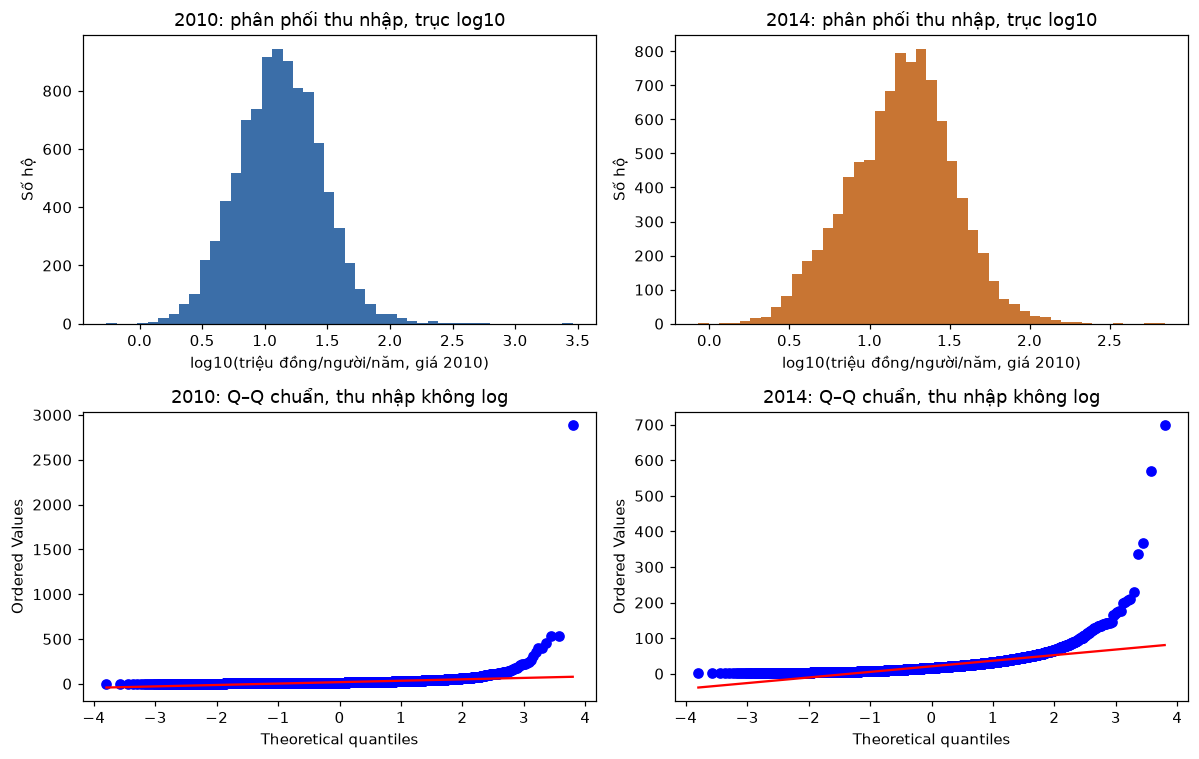

In [5]:
figure, axes = plt.subplots(2, 2, figsize=(11, 7))
for column, year in enumerate(YEARS):
    values = income_samples[(year, "All")]
    # Log chỉ dùng cho hình để nhìn rõ đuôi; mọi test vẫn dùng thu nhập gốc đã quy CPI.
    axes[0, column].hist(np.log10(values), bins=45, color=["#3B6EA8", "#C87533"][column])
    axes[0, column].set_title(f"{year}: phân phối thu nhập, trục log10")
    axes[0, column].set_xlabel("log10(triệu đồng/người/năm, giá 2010)")
    axes[0, column].set_ylabel("Số hộ")
    stats.probplot(values, dist="norm", plot=axes[1, column])
    axes[1, column].set_title(f"{year}: Q–Q chuẩn, thu nhập không log")
figure.tight_layout()
plt.show()

**Cách đọc diagnostics:** tất cả các mẫu bác bỏ chuẩn. Q1–Q3 có nhiều hộ và không có một điểm chi phối SS; t mẫu lớn có cơ sở xấp xỉ tốt hơn. Toàn mẫu và Q4, đặc biệt năm 2010, nhạy với thu nhập lớn: không gọi p/CI của các phần này là đã được xác nhận chính xác. Không tự xóa hộ chỉ vì thu nhập cao.

Phần mean vẫn tính theo Chap 7 §7.2.4 và CLT, nhưng kết luận ghi rõ **theo xấp xỉ**. Riêng F so phương sai cần chuẩn mạnh hơn, nên không dùng để kết luận khi diagnostics này không phù hợp.

In [6]:
largest_income_households = income_data.loc[
    income_data.groupby("year")["real_income_per_person"].idxmax(),
    ["year", "excel_row", "province", "area", "Quart", "income", "size", "real_income_per_person"],
]
display(largest_income_households)

influence_rows = []
for year in YEARS:
    values = income_samples[(year, "All")]
    # Leave-one-out chỉ là chẩn đoán ảnh hưởng, không thay thế mẫu chính.
    without_largest = np.delete(values, np.argmax(values))
    influence_rows.append({
        "year": year,
        "full_sample_mean": values.mean(),
        "mean_without_one_largest": without_largest.mean(),
        "full_sample_variance": values.var(ddof=1),
        "variance_without_one_largest": without_largest.var(ddof=1),
    })
influence_check = pd.DataFrame(influence_rows)
display(influence_check)

,year,excel_row,province,area,Quart,income,size,real_income_per_person
6662,2010,6664,74,2,4,"8,655,550.0000",3,"2,885.1833"
16511,2014,7114,77,2,4,"4,014,000.0000",4,698.3785


,year,full_sample_mean,mean_without_one_largest,full_sample_variance,variance_without_one_largest
0,2010,18.2571,17.9520,"1,286.3879",411.7626
1,2014,20.8607,20.7886,407.8655,359.0499


## 3. Câu 1 — Thu nhập bình quân đầu người có tăng không?

- **Mẫu A:** 9.398 giá trị thu nhập thực đầu người của hộ năm 2014.
- **Mẫu B:** 9.399 giá trị tương ứng của hộ năm 2010.
- **Tham số:** $\Delta_\mu=\mu_{2014}-\mu_{2010}$.
- **H₀:** $\Delta_\mu=0$; **H₁:** $\Delta_\mu>0$.
- **Estimator:** $\widehat\Delta_\mu=\bar Y_{2014}-\bar Y_{2010}$.
- **Test:** hai mẫu độc lập, hai phương sai tổng thể **chưa biết, không giả sử bằng nhau**, **một phía phải** — Chap 7 §7.2.4. Không phải paired, known variance hay one-sample test.

Dưới H₀, $\Delta_\mu=0$:

\[
a=\frac{S_{14}^2}{n_{14}},\quad b=\frac{S_{10}^2}{n_{10}},\quad
SE=\sqrt{a+b},\quad T=\frac{\bar Y_{14}-\bar Y_{10}}{SE},\qquad
\nu=\frac{(a+b)^2}{a^2/(n_{14}-1)+b^2/(n_{10}-1)}.
\]

Dùng $T\approx t_\nu$, p một phía phải $P(t_\nu\ge T_{obs})$. Bác bỏ khi p < 0,05. Báo thêm CI hai phía 95%: $\widehat\Delta\pm t_{\nu,0.975}SE$ và cận dưới một phía 95%: $\widehat\Delta-t_{\nu,0.95}SE$; hai loại khoảng không có cùng ngưỡng.

In [7]:
def independent_mean_increase_test(income_2014, income_2010):
    values_2014 = np.asarray(income_2014, dtype=float)
    values_2010 = np.asarray(income_2010, dtype=float)
    n_2014, n_2010 = len(values_2014), len(values_2010)
    mean_2014, mean_2010 = values_2014.mean(), values_2010.mean()
    variance_2014 = values_2014.var(ddof=1)
    variance_2010 = values_2010.var(ddof=1)
    variance_part_2014 = variance_2014 / n_2014
    variance_part_2010 = variance_2010 / n_2010
    standard_error = np.sqrt(variance_part_2014 + variance_part_2010)
    degrees_of_freedom = (variance_part_2014 + variance_part_2010) ** 2 / (
        variance_part_2014 ** 2 / (n_2014 - 1)
        + variance_part_2010 ** 2 / (n_2010 - 1)
    )
    mean_change = mean_2014 - mean_2010
    t_statistic = mean_change / standard_error
    p_one_sided = stats.t.sf(t_statistic, df=degrees_of_freedom)
    critical_t = stats.t.ppf(1 - SIGNIFICANCE_LEVEL, df=degrees_of_freedom)
    ci_margin = stats.t.ppf(0.975, df=degrees_of_freedom) * standard_error
    scipy_result = stats.ttest_ind(
        values_2014, values_2010, equal_var=False, alternative="greater"
    )
    np.testing.assert_allclose(t_statistic, scipy_result.statistic)
    np.testing.assert_allclose(degrees_of_freedom, scipy_result.df)
    np.testing.assert_allclose(p_one_sided, scipy_result.pvalue, atol=0, rtol=1e-10)
    scipy_two_sided_result = stats.ttest_ind(
        values_2014, values_2010, equal_var=False, alternative="two-sided"
    )
    np.testing.assert_allclose(
        [mean_change - ci_margin, mean_change + ci_margin],
        scipy_two_sided_result.confidence_interval(confidence_level=0.95),
    )
    return {
        "n_2010": n_2010, "n_2014": n_2014,
        "mean_2010": mean_2010, "mean_2014": mean_2014,
        "mean_change": mean_change, "change_percent": 100 * mean_change / mean_2010,
        "SE": standard_error, "t": t_statistic, "df": degrees_of_freedom,
        "critical_t_right_5pct": critical_t, "p_one_sided": p_one_sided,
        "CI95_low": mean_change - ci_margin, "CI95_high": mean_change + ci_margin,
        "lower_one_sided_95": mean_change - critical_t * standard_error,
        "reject_H0_under_approximation": bool(p_one_sided < SIGNIFICANCE_LEVEL),
    }

def format_p_value(value):
    return "< 1e-300 (giới hạn số)" if value == 0 else f"{value:.3g}"

overall_mean_result = independent_mean_increase_test(
    income_samples[(2014, "All")], income_samples[(2010, "All")]
)
overall_mean_table = pd.DataFrame([overall_mean_result])
display(overall_mean_table.style.format({"p_one_sided": format_p_value}))

,n_2010,n_2014,mean_2010,mean_2014,mean_change,change_percent,SE,t,df,critical_t_right_5pct,p_one_sided,CI95_low,CI95_high,lower_one_sided_95,reject_H0_under_approximation
0,9399,9398,18.257094,20.860652,2.603558,14.260530,0.424575,6.132159,14813.459505,1.644956,4.44e-10,1.771340,3.435777,1.905152,True


In [8]:
display(Markdown(
    f"**Kết luận câu 1:** Thu nhập thực bình quân tăng từ "
    f"**{overall_mean_result['mean_2010']:.3f}** lên **{overall_mean_result['mean_2014']:.3f}** "
    f"triệu đồng/người/năm, tức **+{overall_mean_result['mean_change']:.3f} triệu "
    f"({overall_mean_result['change_percent']:.2f}%)**. "
    f"Theo t xấp xỉ, p một phía = **{format_p_value(overall_mean_result['p_one_sided'])}**, "
    f"bác bỏ H₀ ở mức 5%. CI hai phía 95% của mức tăng là "
    f"**[{overall_mean_result['CI95_low']:.3f}; {overall_mean_result['CI95_high']:.3f}] triệu**. "
    "Đây là bằng chứng theo mô hình/xấp xỉ, nhạy với đuôi thu nhập; "
    "không đồng nghĩa mọi hộ đều tăng hoặc đã có ước lượng quốc gia theo trọng số."
))

**Kết luận câu 1:** Thu nhập thực bình quân tăng từ **18.257** lên **20.861** triệu đồng/người/năm, tức **+2.604 triệu (14.26%)**. Theo t xấp xỉ, p một phía = **4.44e-10**, bác bỏ H₀ ở mức 5%. CI hai phía 95% của mức tăng là **[1.771; 3.436] triệu**. Đây là bằng chứng theo mô hình/xấp xỉ, nhạy với đuôi thu nhập; không đồng nghĩa mọi hộ đều tăng hoặc đã có ước lượng quốc gia theo trọng số.

**Ghi chú của mình:**

_Có thể ghi thêm cách hiểu kết quả câu 1 tại đây._

## 4. Câu 2 — Thu nhập bình quân trong từng Q có tăng không?

Với mỗi $q\in\{1,2,3,4\}$:

\[
\Delta_q=\mu_{q,2014}-\mu_{q,2010},\qquad
H_{0,q}:\Delta_q=0,\quad H_{1,q}:\Delta_q>0.
\]

Estimator là $\bar Y_{q,2014}-\bar Y_{q,2010}$; dùng **cùng t hai mẫu độc lập, phương sai chưa biết/không giả sử bằng nhau, một phía phải**, đúng nhóm q ở hai năm — Chap 7 §7.2.4.

Không đưa bốn mean Q vào làm bốn quan sát. Mỗi test dùng khoảng 2.350 hộ/năm. Nhãn Q được giữ theo Excel, không chia lại; Q1 năm 2014 có thể gồm các hộ khác Q1 năm 2010. Các nhóm Q1–Q3 bị giới hạn khoảng thu nhập theo cách phân nhóm, nên không kỳ vọng thu nhập từng hộ chuẩn; dùng xấp xỉ mẫu lớn cho mean, có kiểm tra ảnh hưởng.

In [9]:
quartile_results = []
for quartile in [1, 2, 3, 4]:
    scope = f"Q{quartile}"
    result = independent_mean_increase_test(
        income_samples[(2014, scope)], income_samples[(2010, scope)]
    )
    quartile_results.append({"scope": scope, **result})

quartile_mean_table = pd.DataFrame(quartile_results)
display(quartile_mean_table[[
    "scope", "n_2010", "n_2014", "mean_2010", "mean_2014", "mean_change", "change_percent",
    "SE", "t", "df", "p_one_sided", "CI95_low", "CI95_high",
    "reject_H0_under_approximation",
]].style.format({"p_one_sided": format_p_value}))

,scope,n_2010,n_2014,mean_2010,mean_2014,mean_change,change_percent,SE,t,df,p_one_sided,CI95_low,CI95_high,reject_H0_under_approximation
0,Q1,2350,2352,5.256769,6.291917,1.035148,19.691712,0.053226,19.448031,4476.962319,3.04e-81,0.930798,1.139498,True
1,Q2,2349,2350,10.382223,13.024193,2.641970,25.447056,0.050953,51.850988,4432.113760,< 1e-300 (giới hạn số),2.542077,2.741864,True
2,Q3,2350,2347,17.092934,20.757957,3.665023,21.441743,0.076845,47.693516,4687.275956,< 1e-300 (giới hạn số),3.514370,3.815676,True
3,Q4,2350,2349,40.293097,43.390395,3.097298,7.686921,1.495038,2.071719,3207.141459,0.0192,0.165972,6.028625,True


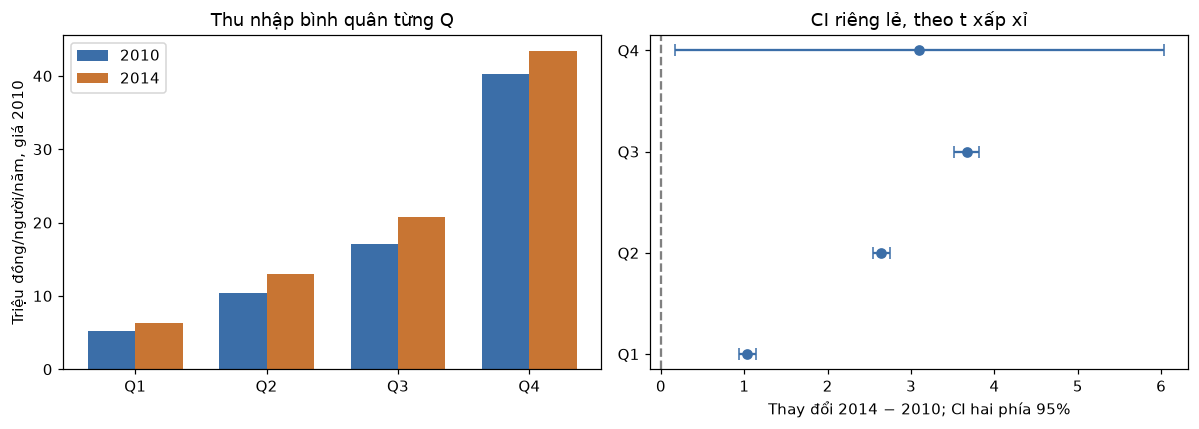

In [10]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
positions = np.arange(4)
for year, shift, color in [(2010, -0.18, "#3B6EA8"), (2014, 0.18, "#C87533")]:
    axes[0].bar(positions + shift, quartile_mean_table[f"mean_{year}"],
                width=0.36, label=str(year), color=color)
axes[0].set_xticks(positions, quartile_mean_table["scope"])
axes[0].set_ylabel("Triệu đồng/người/năm, giá 2010")
axes[0].set_title("Thu nhập bình quân từng Q")
axes[0].legend()

axes[1].errorbar(
    quartile_mean_table["mean_change"], positions,
    xerr=[quartile_mean_table["mean_change"] - quartile_mean_table["CI95_low"],
          quartile_mean_table["CI95_high"] - quartile_mean_table["mean_change"]],
    fmt="o", color="#3B6EA8", capsize=4,
)
axes[1].axvline(0, color="grey", linestyle="--")
axes[1].set_yticks(positions, quartile_mean_table["scope"])
axes[1].set_xlabel("Thay đổi 2014 − 2010; CI hai phía 95%")
axes[1].set_title("CI riêng lẻ, theo t xấp xỉ")
figure.tight_layout()
plt.show()

In [11]:
quartile_conclusions = []
for result in quartile_results:
    decision = "bác bỏ H₀" if result["reject_H0_under_approximation"] else "không bác bỏ H₀"
    quartile_conclusions.append(
        f"- **{result['scope']}:** +{result['mean_change']:.3f} triệu "
        f"({result['change_percent']:.2f}%); p = {format_p_value(result['p_one_sided'])}; "
        f"{decision} theo t xấp xỉ."
    )
display(Markdown(
    "**Kết luận câu 2, từng test ở mức 5%:**\n\n"
    + "\n".join(quartile_conclusions)
    + "\n\nQ1–Q3 không có một quan sát chi phối SS như Q4. "
    "Kết quả Q4 (p khoảng 0,019) cần thận trọng hơn vì đuôi mạnh. "
    "Không suy mức tăng giữa các Q khác nhau từ việc so các p riêng."
))

**Kết luận câu 2, từng test ở mức 5%:**

- **Q1:** +1.035 triệu (19.69%); p = 3.04e-81; bác bỏ H₀ theo t xấp xỉ.
- **Q2:** +2.642 triệu (25.45%); p = < 1e-300 (giới hạn số); bác bỏ H₀ theo t xấp xỉ.
- **Q3:** +3.665 triệu (21.44%); p = < 1e-300 (giới hạn số); bác bỏ H₀ theo t xấp xỉ.
- **Q4:** +3.097 triệu (7.69%); p = 0.0192; bác bỏ H₀ theo t xấp xỉ.

Q1–Q3 không có một quan sát chi phối SS như Q4. Kết quả Q4 (p khoảng 0,019) cần thận trọng hơn vì đuôi mạnh. Không suy mức tăng giữa các Q khác nhau từ việc so các p riêng.

**Ghi chú của mình:**

_Có thể ghi thêm nhóm nào tăng nhiều theo tiền, nhóm nào tăng nhiều theo phần trăm._

## 5. Câu 3 — Phương sai thu nhập có giảm không?

**Định nghĩa câu hỏi:** phương sai của **thu nhập thực đầu người**, đơn vị $(triệu\ đồng/người/năm)^2$. Đây là phân tán tuyệt đối, không phải Gini hay bất bình đẳng tương đối. Đổi CPI phải đổi cả phương sai theo **bình phương hệ số**.

\[
R_\sigma=\frac{\sigma_{2014}^2}{\sigma_{2010}^2},\qquad
H_0:R_\sigma=1,\quad H_1:R_\sigma<1,\qquad
\widehat R_\sigma=\frac{S_{2014}^2}{S_{2010}^2}.
\]

Theo **Chap 7 §7.3**, nếu hai mẫu độc lập và **hai tổng thể chuẩn**, dưới H₀:

\[
F=\frac{S_{2014}^2}{S_{2010}^2}\sim F_{n_{2014}-1,n_{2010}-1}.
\]

Đây là **F-test hai phương sai, một phía trái**, không phải ANOVA.

**Điểm quyết định:** quan hệ với F đến từ phân phối χ² của phương sai mẫu khi tổng thể chuẩn (Chap 3 trang 17). CLT cho **mean** không tự khiến tỷ số phương sai có phân phối F khi thu nhập không chuẩn. Diagnostics cho thấy lệch rất mạnh và một quan sát chi phối, nên **không tính p/CI theo F để kết luận cho dữ liệu này**.

In [12]:
overall_income_2010 = income_samples[(2010, "All")]
overall_income_2014 = income_samples[(2014, "All")]
variance_2010 = overall_income_2010.var(ddof=1)
variance_2014 = overall_income_2014.var(ddof=1)
sample_variance_ratio = variance_2014 / variance_2010
variance_change_percent = 100 * (sample_variance_ratio - 1)

# Kiểm tra quy đổi phương sai dùng bình phương hệ số CPI.
for year in YEARS:
    year_rows = income_data.loc[income_data["year"].eq(year)]
    np.testing.assert_allclose(
        year_rows["real_income_per_person"].var(ddof=1),
        year_rows["nominal_income_per_person"].var(ddof=1) * (100 / cpi_by_year.loc[year]) ** 2,
    )

normality_rows = distribution_checks.loc[distribution_checks["scope"].eq("All")]
f_normal_model_supported = not normality_rows["reject_normality_5pct"].any()
variance_result = pd.DataFrame([{
    "variance_2010": variance_2010, "variance_2014": variance_2014,
    "sample_ratio_2014_over_2010": sample_variance_ratio,
    "sample_change_percent": variance_change_percent,
    "F_normal_model_supported": f_normal_model_supported,
    "F_p_value": np.nan,  # Không ép p theo F khi chuẩn không phù hợp.
}])
display(variance_result)
display(influence_check[["year", "full_sample_variance", "variance_without_one_largest"]])

,variance_2010,variance_2014,sample_ratio_2014_over_2010,sample_change_percent,F_normal_model_supported,F_p_value
0,"1,286.3879",407.8655,0.3171,-68.2937,False,NaN


,year,full_sample_variance,variance_without_one_largest
0,2010,"1,286.3879",411.7626
1,2014,407.8655,359.0499


In [13]:
display(Markdown(
    f"**Kết luận câu 3:** Phương sai **mẫu** giảm từ **{variance_2010:.3f}** "
    f"xuống **{variance_2014:.3f}**, tương đương **{-variance_change_percent:.2f}%**. "
    "Nhưng **chưa có kết luận kiểm định hợp lệ rằng phương sai tổng thể giảm bằng F-test trong lớp**. "
    "Không đưa ra quyết định bác bỏ/không bác bỏ H₀ vì mô hình phân phối F không phù hợp. "
    "Số giảm mạnh chịu ảnh hưởng lớn của đuôi năm 2010: bỏ riêng một điểm lớn nhất "
    "để chẩn đoán làm phương sai 2010 xuống khoảng 411,763, gần mức 407,866 của 2014. "
    "Đây không phải lý do xóa điểm đó khỏi mẫu chính, cũng không phải chứng minh nó sai."
))

**Kết luận câu 3:** Phương sai **mẫu** giảm từ **1286.388** xuống **407.866**, tương đương **68.29%**. Nhưng **chưa có kết luận kiểm định hợp lệ rằng phương sai tổng thể giảm bằng F-test trong lớp**. Không đưa ra quyết định bác bỏ/không bác bỏ H₀ vì mô hình phân phối F không phù hợp. Số giảm mạnh chịu ảnh hưởng lớn của đuôi năm 2010: bỏ riêng một điểm lớn nhất để chẩn đoán làm phương sai 2010 xuống khoảng 411,763, gần mức 407,866 của 2014. Đây không phải lý do xóa điểm đó khỏi mẫu chính, cũng không phải chứng minh nó sai.

**Ghi chú của mình:**

_Phân biệt “phương sai trong mẫu giảm” và “có bằng chứng phương sai tổng thể giảm”._

## 6. Câu 4 — Gap Q4 − Q1 có giảm không?

**Gap chính là khoảng cách tuyệt đối giữa hai mean**, không phải khoảng cách giữa hai hộ cực trị:

\[
G_t=\mu_{Q4,t}-\mu_{Q1,t},\qquad
\Delta_G=G_{2014}-G_{2010}.
\]

- **H₀:** $\Delta_G=0$; **H₁:** $\Delta_G<0$.
- **Estimator:** $\widehat\Delta_G=(\bar Y_{4,14}-\bar Y_{1,14})-(\bar Y_{4,10}-\bar Y_{1,10})$.
- **Sample:** bốn vector hộ Q4/2014, Q1/2014, Q4/2010, Q1/2010. Giữ nhãn Q như đã cho và mô hình hóa các nhóm độc lập; chưa tính sự bất định của cách xếp Q theo mẫu.

**Tính từ kiến thức lớp:** Chap 3 cho $Var(\bar Y)=\sigma^2/n$ và CLT. Với tổ hợp các mean độc lập, $Var(\sum c_j\bar Y_j)=\sum c_j^2Var(\bar Y_j)$. Ở đây $c=(1,-1,-1,1)$ nên:

\[
\widehat{SE}^2=\frac{S^2_{4,14}}{n_{4,14}}+
\frac{S^2_{1,14}}{n_{1,14}}+
\frac{S^2_{4,10}}{n_{4,10}}+
\frac{S^2_{1,10}}{n_{1,10}},\qquad
Z_G=\frac{\widehat\Delta_G}{\widehat{SE}}\overset{H_0}{\approx}N(0,1).
\]

Đây là **kiểm định một tương phản bốn mean bằng xấp xỉ chuẩn mẫu lớn**, suy từ CLT; **không phải known-variance Z-test** và không gọi là công thức t hai mẫu nguyên dạng ở Chap 7. Phương sai chưa biết được ước lượng riêng. p phía trái là $\Phi(Z_G)$; bác bỏ khi $Z_G<-1,645$ ở mức 5%.

Không lấy “hai gap năm” làm một mẫu n = 2, không paired hai hộ Q1/Q4 và không suy gap thay đổi từ hai p-value của câu 2. Xấp xỉ vẫn nhạy với đuôi Q4; chưa tự động bảo đảm chỉ vì n lớn.

In [14]:
gap_components = [
    (2014, "Q4", 1), (2014, "Q1", -1),
    (2010, "Q4", -1), (2010, "Q1", 1),
]
gap_component_rows = []
for year, scope, coefficient in gap_components:
    values = income_samples[(year, scope)]
    gap_component_rows.append({
        "year": year, "scope": scope, "coefficient": coefficient,
        "n": len(values), "mean": values.mean(), "sample_variance": values.var(ddof=1),
        "variance_part": coefficient ** 2 * values.var(ddof=1) / len(values),
    })
gap_component_table = pd.DataFrame(gap_component_rows)
display(gap_component_table)

gap_2010 = income_samples[(2010, "Q4")].mean() - income_samples[(2010, "Q1")].mean()
gap_2014 = income_samples[(2014, "Q4")].mean() - income_samples[(2014, "Q1")].mean()
gap_change = gap_2014 - gap_2010
gap_standard_error = np.sqrt(gap_component_table["variance_part"].sum())
gap_z_statistic = gap_change / gap_standard_error
gap_p_one_sided = stats.norm.cdf(gap_z_statistic)
gap_critical_z = stats.norm.ppf(SIGNIFICANCE_LEVEL)
gap_ci_margin = stats.norm.ppf(0.975) * gap_standard_error
gap_upper_one_sided_95 = gap_change + stats.norm.ppf(0.95) * gap_standard_error

gap_result = pd.DataFrame([{
    "gap_2010": gap_2010, "gap_2014": gap_2014, "gap_change": gap_change,
    "SE": gap_standard_error, "Z": gap_z_statistic,
    "critical_Z_left_5pct": gap_critical_z, "p_one_sided": gap_p_one_sided,
    "CI95_low": gap_change - gap_ci_margin, "CI95_high": gap_change + gap_ci_margin,
    "upper_one_sided_95": gap_upper_one_sided_95,
    "reject_H0_under_approximation": bool(gap_p_one_sided < SIGNIFICANCE_LEVEL),
}])
display(gap_result)

,year,scope,coefficient,n,mean,sample_variance,variance_part
0,2014,Q4,1,2349,43.3904,835.3616,0.3556
1,2014,Q1,-1,2352,6.2919,4.0767,0.0017
2,2010,Q4,-1,2350,40.2931,"4,416.8571",1.8795
3,2010,Q1,1,2350,5.2568,2.5844,0.0011


,gap_2010,gap_2014,gap_change,SE,Z,critical_Z_left_5pct,p_one_sided,CI95_low,CI95_high,upper_one_sided_95,reject_H0_under_approximation
0,35.0363,37.0985,2.0622,1.4960,1.3785,-1.6449,0.9160,-0.8699,4.9942,4.5228,False


In [15]:
gap_ratio_rows = []
for year in YEARS:
    mean_q1 = income_samples[(year, "Q1")].mean()
    mean_q4 = income_samples[(year, "Q4")].mean()
    gap_ratio_rows.append({
        "year": year, "Q1_mean": mean_q1, "Q4_mean": mean_q4,
        "absolute_gap_Q4_minus_Q1": mean_q4 - mean_q1,
        "relative_ratio_Q4_over_Q1": mean_q4 / mean_q1,
    })
gap_comparison = pd.DataFrame(gap_ratio_rows)
display(gap_comparison)
display(Markdown(
    f"**Kết luận câu 4:** Gap tuyệt đối trong mẫu tăng từ **{gap_2010:.3f}** "
    f"lên **{gap_2014:.3f}** triệu đồng/người/năm, chênh **+{gap_change:.3f} triệu**. "
    f"Test CLT phía giảm có Z = **{gap_z_statistic:.3f}**, p = **{gap_p_one_sided:.3f}**: "
    "**không bác bỏ H₀; chưa có bằng chứng gap tuyệt đối giảm**. "
    "Kết quả này cũng chưa chứng minh gap tổng thể tăng hoặc không đổi, và xấp xỉ còn nhạy với Q4. "
    "Trong khi đó, tỷ số Q4/Q1 trong mẫu giảm từ khoảng **7,665** xuống **6,896 lần**. "
    "Tỷ số chỉ mô tả, chưa được kiểm định ở đây; hai thước đo trả lời hai câu hỏi khác nhau."
))

,year,Q1_mean,Q4_mean,absolute_gap_Q4_minus_Q1,relative_ratio_Q4_over_Q1
0,2010,5.2568,40.2931,35.0363,7.6650
1,2014,6.2919,43.3904,37.0985,6.8962


**Kết luận câu 4:** Gap tuyệt đối trong mẫu tăng từ **35.036** lên **37.098** triệu đồng/người/năm, chênh **+2.062 triệu**. Test CLT phía giảm có Z = **1.378**, p = **0.916**: **không bác bỏ H₀; chưa có bằng chứng gap tuyệt đối giảm**. Kết quả này cũng chưa chứng minh gap tổng thể tăng hoặc không đổi, và xấp xỉ còn nhạy với Q4. Trong khi đó, tỷ số Q4/Q1 trong mẫu giảm từ khoảng **7,665** xuống **6,896 lần**. Tỷ số chỉ mô tả, chưa được kiểm định ở đây; hai thước đo trả lời hai câu hỏi khác nhau.

**Ghi chú của mình:**

_Q1 có thể tăng nhanh hơn theo phần trăm, nhưng Q4 vẫn tăng nhiều hơn theo số tiền. Vì vậy tỷ số giảm và chênh lệch tiền tăng có thể cùng xảy ra._

## 7. Tổng hợp và kiểm tra kết quả

Bảng dưới tách **thay đổi quan sát trong mẫu** và **suy luận theo mô hình**. “Không có bằng chứng giảm” không có nghĩa đã chứng minh bằng nhau. Không thay phương sai bằng CV hoặc gap tuyệt đối bằng tỷ số để đổi câu hỏi sau khi xem kết quả.

In [16]:
final_summary = pd.DataFrame([
    {
        "question": "1. Mean toàn mẫu tăng?",
        "observed_change": f"+{overall_mean_result['mean_change']:.3f} triệu; +{overall_mean_result['change_percent']:.2f}%",
        "inference": "Bác bỏ H₀ theo t xấp xỉ; nhạy đuôi thu nhập",
    },
    {
        "question": "2. Mean từng Q tăng?",
        "observed_change": "; ".join(f"{r['scope']}: +{r['mean_change']:.3f}" for r in quartile_results),
        "inference": "Cả 4 test riêng lẻ bác bỏ theo t xấp xỉ; Q4 cần thận trọng hơn",
    },
    {
        "question": "3. Variance toàn mẫu giảm?",
        "observed_change": f"{variance_2010:.3f} → {variance_2014:.3f}; {variance_change_percent:.2f}%",
        "inference": "Mẫu giảm; không quyết định H₀ bằng F vì điều kiện chuẩn không phù hợp",
    },
    {
        "question": "4. Gap Q4 − Q1 giảm?",
        "observed_change": f"{gap_2010:.3f} → {gap_2014:.3f}; +{gap_change:.3f} triệu",
        "inference": f"Không bác bỏ H₀ theo CLT (p={gap_p_one_sided:.3f}); chưa có bằng chứng giảm",
    },
])
display(final_summary.style.set_properties(**{"white-space": "normal", "text-align": "left"}))

,question,observed_change,inference
0,1. Mean toàn mẫu tăng?,+2.604 triệu; +14.26%,Bác bỏ H₀ theo t xấp xỉ; nhạy đuôi thu nhập
1,2. Mean từng Q tăng?,Q1: +1.035; Q2: +2.642; Q3: +3.665; Q4: +3.097,Cả 4 test riêng lẻ bác bỏ theo t xấp xỉ; Q4 cần thận trọng hơn
2,3. Variance toàn mẫu giảm?,1286.388 → 407.866; -68.29%,Mẫu giảm; không quyết định H₀ bằng F vì điều kiện chuẩn không phù hợp
3,4. Gap Q4 − Q1 giảm?,35.036 → 37.098; +2.062 triệu,Không bác bỏ H₀ theo CLT (p=0.916); chưa có bằng chứng giảm


In [17]:
# Kiểm tra trực tiếp các đại lượng cần cho câu hỏi, không thay dữ liệu.
for year in YEARS:
    whole_sample = income_samples[(year, "All")]
    groups = [income_samples[(year, f"Q{q}")] for q in [1, 2, 3, 4]]
    assert sum(len(group) for group in groups) == len(whole_sample)
    weighted_group_mean = sum(len(group) * group.mean() for group in groups) / len(whole_sample)
    np.testing.assert_allclose(weighted_group_mean, whole_sample.mean())

np.testing.assert_allclose(
    gap_change,
    quartile_mean_table.set_index("scope").loc["Q4", "mean_change"]
    - quartile_mean_table.set_index("scope").loc["Q1", "mean_change"],
)
np.testing.assert_allclose(
    gap_change,
    (gap_component_table["coefficient"] * gap_component_table["mean"]).sum(),
)
np.testing.assert_allclose(
    gap_standard_error ** 2,
    sum(stats.sem(income_samples[(year, scope)]) ** 2 for year, scope, _ in gap_components),
)
assert len(income_samples) == 10
assert not f_normal_model_supported
print("Đã đối chiếu 5 t-test/df/p/CI với SciPy; kiểm tra CPI–variance, n các Q, mean toàn mẫu và SE của gap.")
print("Không xóa thu nhập lớn, không sửa Excel gốc, không đưa p F không hợp lệ vào kết luận.")

Đã đối chiếu 5 t-test/df/p/CI với SciPy; kiểm tra CPI–variance, n các Q, mean toàn mẫu và SE của gap.
Không xóa thu nhập lớn, không sửa Excel gốc, không đưa p F không hợp lệ vào kết luận.


**Phạm vi kết luận cuối cùng:** bài đo thu nhập thực bình quân và phân tán thu nhập của các hộ trong mẫu. Chưa đo đầy đủ mức sống, chưa theo cùng hộ, chưa hiệu chỉnh khảo sát quốc gia và chưa bảo đảm p/CI hữu hạn mẫu khi đuôi rất mạnh. Kiến thức lớp trả lời được các câu mean bằng xấp xỉ; câu phương sai hiện có kết luận mô tả, chưa có kiểm định F hợp lệ.